# 七币种 DQN 门控策略回测

**币种**：BTC、ETH、BNB、PAXG、SOL、TRX、XLM（小时频 OHLCV）

**策略配置**（各币种一致）：
- 动态带：日频等价映射（`mid=MA(60)`、`half=4×ATR(14)`，shift(1)+ffill 到小时频）
- 门控：1h DQN，A1 账户状态（`position_ratio` + `cash_ratio`），R0 奖励，100k 步，seed 42
- 每格名义金额 ≈ 1000 USDT，初始底仓 50%，手续费 0.1%
- 训练集：2022-01-01 ~ 2025-12-31；测试集：2026-01-01 ~ 2026-07-31

**模型统一保存至 `models/`**，结果保存至 `data/multi_coin_dqn_results.csv`。

In [1]:
from pathlib import Path
import sys
import warnings

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebook":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({
    "font.family": "Noto Sans CJK SC",
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
warnings.filterwarnings("ignore")
print("项目根目录:", PROJECT_ROOT)

/home/nullwinters/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-qkdyv7h6 because there was an issue with the default path ({configdir}); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


项目根目录: /home/nullwinters/Projects/CryptoGrid


In [2]:
# ================= 数据校验（duckdb） =================
coins = ["BTC", "ETH", "BNB", "PAXG", "SOL", "TRX", "XLM"]
rows = []
for c in coins:
    path = PROJECT_ROOT / "data" / f"{c.lower()}_usdt_1h.csv"
    q = f"""
    SELECT min(timestamp) AS t0, max(timestamp) AS t1, count(*) AS n,
           count(*) FILTER (WHERE timestamp >= '2022-01-01' AND timestamp <= '2025-12-31 23:00:00') AS train_n,
           count(*) FILTER (WHERE timestamp >= '2026-01-01' AND timestamp <= '2026-07-31 23:00:00') AS test_n
    FROM read_csv_auto('{path}')
    """
    r = duckdb.connect().execute(q).fetchdf().iloc[0].to_dict()
    r["coin"] = c
    rows.append(r)
df_check = pd.DataFrame(rows)[["coin", "n", "t0", "t1", "train_n", "test_n"]]
df_check["t0"] = df_check["t0"].astype(str)
df_check["t1"] = df_check["t1"].astype(str)
df_check

,coin,n,t0,t1,train_n,test_n
0,BTC,49233,2021-01-01,2026-08-14 08:00:00,35064,5088
1,ETH,49234,2021-01-01,2026-08-14 09:00:00,35064,5088
2,BNB,49235,2021-01-01,2026-08-14 10:00:00,35064,5088
3,PAXG,49236,2021-01-01,2026-08-14 11:00:00,35064,5088
4,SOL,49234,2021-01-01,2026-08-14 09:00:00,35064,5088
5,TRX,49234,2021-01-01,2026-08-14 09:00:00,35064,5088
6,XLM,49235,2021-01-01,2026-08-14 10:00:00,35064,5088


In [3]:
# ================= 结果加载（如缺失则运行训练脚本） =================
import subprocess, os
RESULT_CSV = PROJECT_ROOT / "data" / "multi_coin_dqn_results.csv"
if not RESULT_CSV.exists():
    print("结果 CSV 不存在，开始训练七币种模型（约 8~12 分钟）...")
    r = subprocess.run(
        [sys.executable, str(PROJECT_ROOT / "scripts" / "multi_coin_dqn.py")],
        capture_output=True, text=True, cwd=PROJECT_ROOT,
    )
    print(r.stdout[-2000:])
    if r.returncode != 0:
        print(r.stderr)
        raise RuntimeError("multi_coin_dqn.py 执行失败")

df = pd.read_csv(RESULT_CSV)
df["coin"] = df["coin"].astype(str)
print("模型目录:", PROJECT_ROOT / "models")
print("模型文件:", sorted([p.name for p in (PROJECT_ROOT / 'models').glob('*.zip')]))
df.head()

模型目录: /home/nullwinters/Projects/CryptoGrid/models
模型文件: ['dqn_gate_bnb_a1_1h.zip', 'dqn_gate_btc_a1_1h.zip', 'dqn_gate_eth_a1_1h.zip', 'dqn_gate_paxg_a1_1h.zip', 'dqn_gate_sol_a1_1h.zip', 'dqn_gate_trx_a1_1h.zip', 'dqn_gate_xlm_a1_1h.zip']


,coin,model,train_s,action0_ratio,rl_ret,rl_dd,rl_sharpe,rl_calmar,rl_end_nav,rl_trades,...,ma_gate_sharpe,ma_gate_calmar,ma_gate_end_nav,ma_gate_trades,ma_gate_reanchor,ma_gate_switch,bh_ret,bh_dd,bh_sharpe,bh_end_nav
0,BTC,/home/nullwinters/Projects/CryptoGrid/models/d...,74.1,0.442807,-0.075104,-0.149755,-0.986268,-0.840042,92443.308966,445,...,-1.248979,-1.119839,86043.406440,646,45,80,-0.284456,-0.402798,-1.045736,71554.381034
1,ETH,/home/nullwinters/Projects/CryptoGrid/models/d...,67.5,0.648978,-0.129165,-0.207041,-1.275598,-1.023591,87039.955803,894,...,-1.313121,-1.035371,81964.688838,1052,19,33,-0.375082,-0.550847,-1.039763,62491.824832
2,BNB,/home/nullwinters/Projects/CryptoGrid/models/d...,103.4,0.451454,-0.123761,-0.177410,-1.415986,-1.146972,87580.125219,382,...,-1.425347,-1.168624,83794.168935,588,33,61,-0.323167,-0.431788,-1.227124,67683.278371
3,PAXG,/home/nullwinters/Projects/CryptoGrid/models/d...,118.8,0.403105,0.131790,-0.014760,3.297285,16.098998,113122.452130,332,...,1.174531,2.888026,110320.812434,884,29,51,-0.053854,-0.299446,0.172218,94614.623597
4,SOL,/home/nullwinters/Projects/CryptoGrid/models/d...,99.5,0.331368,-0.141775,-0.231340,-1.338118,-1.000579,85779.568058,495,...,-1.373064,-1.053343,78866.327323,672,67,130,-0.419383,-0.588483,-1.097023,58061.688053


In [4]:
# ================= 结果汇总表 =================
summary_cols = ["coin",
                "rl_ret", "rl_dd", "rl_sharpe", "rl_trades", "rl_switch",
                "ma_gate_ret", "ma_gate_dd", "ma_gate_sharpe", "ma_gate_trades",
                "no_gate_ret", "no_gate_dd", "no_gate_sharpe", "no_gate_trades",
                "bh_ret", "bh_dd", "bh_sharpe"]
summary = df[summary_cols].copy()
# 收益率与回撤转为百分比；Sharpe 保持原始数值
pct_cols = [c for c in summary.columns if c.endswith("_ret") or c.endswith("_dd")]
for col in pct_cols:
    summary[col] = summary[col] * 100
summary.columns = ["币种",
                   "DQN收益%", "DQN回撤%", "DQN Sharpe", "DQN成交", "DQN切换",
                   "MA收益%", "MA回撤%", "MA Sharpe", "MA成交",
                   "永撤收益%", "永撤回撤%", "永撤 Sharpe", "永撤成交",
                   "B&H收益%", "B&H回撤%", "B&H Sharpe"]
summary["DQN-MA收益差(pp)"] = summary["DQN收益%"] - summary["MA收益%"]
summary["DQN-MA回撤差(pp)"] = summary["DQN回撤%"] - summary["MA回撤%"]
summary = summary.round(3)
summary

,币种,DQN收益%,DQN回撤%,DQN Sharpe,DQN成交,DQN切换,MA收益%,MA回撤%,MA Sharpe,MA成交,永撤收益%,永撤回撤%,永撤 Sharpe,永撤成交,B&H收益%,B&H回撤%,B&H Sharpe,DQN-MA收益差(pp),DQN-MA回撤差(pp)
0,BTC,-7.510,-14.976,-0.986,445,378,-13.914,-20.306,-1.249,646,-15.644,-23.103,-1.135,1501,-28.446,-40.280,-1.046,6.403,5.331
1,ETH,-12.917,-20.704,-1.276,894,470,-17.994,-27.950,-1.313,1052,-20.178,-31.092,-1.278,1898,-37.508,-55.085,-1.040,5.078,7.245
2,BNB,-12.376,-17.741,-1.416,382,400,-16.164,-22.407,-1.425,588,-17.314,-24.517,-1.273,1544,-32.317,-43.179,-1.227,3.788,4.666
3,PAXG,13.179,-1.476,3.297,332,276,10.376,-6.416,1.175,884,19.443,-5.082,1.685,1674,-5.385,-29.945,0.172,2.803,4.940
4,SOL,-14.178,-23.134,-1.338,495,516,-21.094,-31.804,-1.373,672,-22.372,-34.068,-1.309,2109,-41.938,-58.848,-1.097,6.917,8.670
5,TRX,1.701,-6.797,0.603,293,348,2.933,-6.854,0.808,478,2.740,-7.553,0.655,976,14.843,-17.034,1.188,-1.232,0.057
6,XLM,-3.934,-16.749,-0.359,1081,764,-5.265,-24.096,0.021,1551,-1.740,-23.229,0.139,3110,-15.266,-44.765,0.170,1.331,7.347


In [5]:
# ================= 汇总统计 =================
n = len(df)
print(f"币种数: {n}")
print(f"DQN 收益胜 MA 门控: {int((df.rl_ret > df.ma_gate_ret).sum())}/{n}")
print(f"DQN 收益胜 永不撤单: {int((df.rl_ret > df.no_gate_ret).sum())}/{n}")
print(f"DQN 回撤小于 MA 门控: {int((df.rl_dd > df.ma_gate_dd).sum())}/{n}")
print(f"DQN 回撤小于 永不撤单: {int((df.rl_dd > df.no_gate_dd).sum())}/{n}")
print(f"DQN Sharpe 胜 MA 门控: {int((df.rl_sharpe > df.ma_gate_sharpe).sum())}/{n}")
print(f"DQN 收益胜 B&H: {int((df.rl_ret > df.bh_ret).sum())}/{n}")
print()
print("各币种 DQN 相对 MA 门控：")
for _, row in df.iterrows():
    d_ret = (row.rl_ret - row.ma_gate_ret) * 100
    d_dd = (row.rl_dd - row.ma_gate_dd) * 100
    print(f"  {row.coin}: Δ收益 {d_ret:+.2f}pp, Δ回撤 {d_dd:+.2f}pp (正=回撤更小)")

币种数: 7
DQN 收益胜 MA 门控: 6/7
DQN 收益胜 永不撤单: 4/7
DQN 回撤小于 MA 门控: 7/7
DQN 回撤小于 永不撤单: 7/7
DQN Sharpe 胜 MA 门控: 5/7
DQN 收益胜 B&H: 6/7

各币种 DQN 相对 MA 门控：
  BTC: Δ收益 +6.40pp, Δ回撤 +5.33pp (正=回撤更小)
  ETH: Δ收益 +5.08pp, Δ回撤 +7.25pp (正=回撤更小)
  BNB: Δ收益 +3.79pp, Δ回撤 +4.67pp (正=回撤更小)
  PAXG: Δ收益 +2.80pp, Δ回撤 +4.94pp (正=回撤更小)
  SOL: Δ收益 +6.92pp, Δ回撤 +8.67pp (正=回撤更小)
  TRX: Δ收益 -1.23pp, Δ回撤 +0.06pp (正=回撤更小)
  XLM: Δ收益 +1.33pp, Δ回撤 +7.35pp (正=回撤更小)


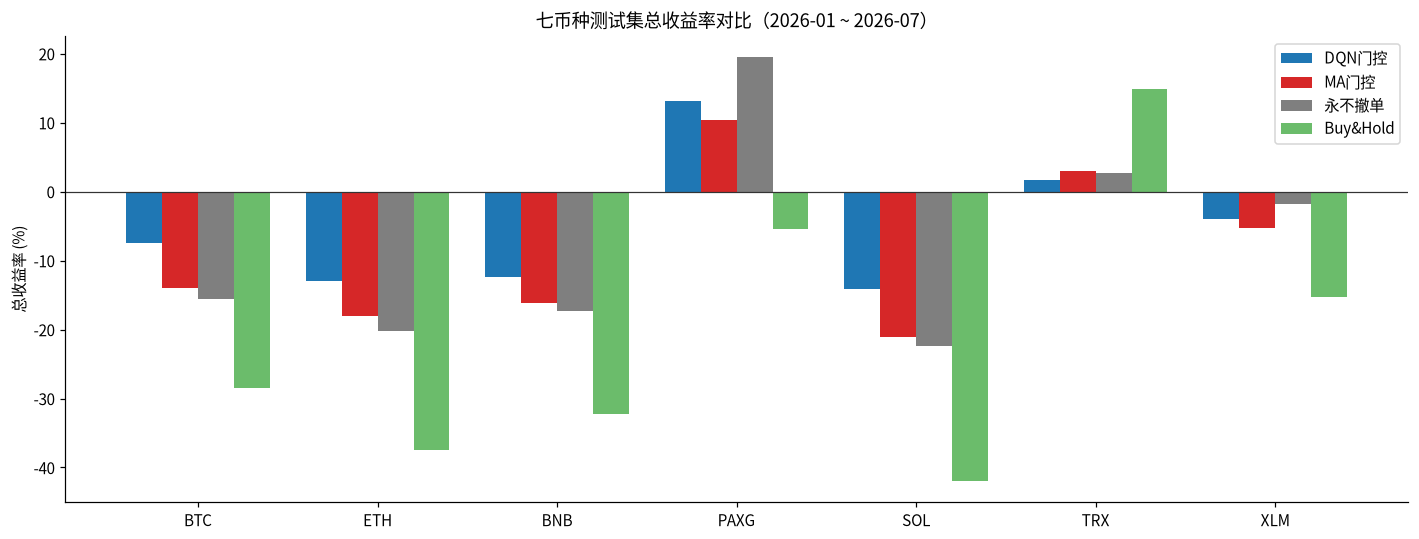

In [6]:
# ================= 图1：各币种收益对比 =================
coins = df["coin"].tolist()
x = np.arange(len(coins)); w = 0.2
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - 1.5*w, df["rl_ret"]*100, w, color="#1f77b4", label="DQN门控")
ax.bar(x - 0.5*w, df["ma_gate_ret"]*100, w, color="#d62728", label="MA门控")
ax.bar(x + 0.5*w, df["no_gate_ret"]*100, w, color="#7f7f7f", label="永不撤单")
ax.bar(x + 1.5*w, df["bh_ret"]*100, w, color="#2ca02c", ls="--", alpha=0.7, label="Buy&Hold")
ax.axhline(0, color="#333", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(coins)
ax.set_ylabel("总收益率 (%)")
ax.set_title("七币种测试集总收益率对比（2026-01 ~ 2026-07）")
ax.legend()
plt.tight_layout()
plt.show()

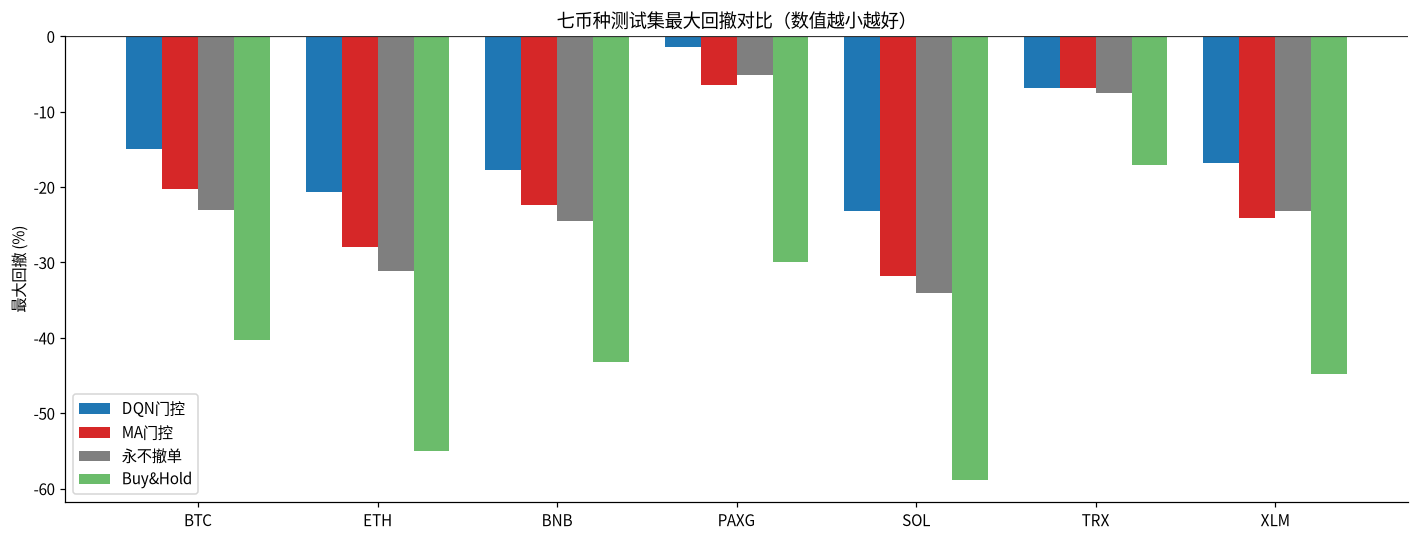

In [7]:
# ================= 图2：各币种最大回撤对比 =================
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - 1.5*w, df["rl_dd"]*100, w, color="#1f77b4", label="DQN门控")
ax.bar(x - 0.5*w, df["ma_gate_dd"]*100, w, color="#d62728", label="MA门控")
ax.bar(x + 0.5*w, df["no_gate_dd"]*100, w, color="#7f7f7f", label="永不撤单")
ax.bar(x + 1.5*w, df["bh_dd"]*100, w, color="#2ca02c", ls="--", alpha=0.7, label="Buy&Hold")
ax.axhline(0, color="#333", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(coins)
ax.set_ylabel("最大回撤 (%)")
ax.set_title("七币种测试集最大回撤对比（数值越小越好）")
ax.legend()
plt.tight_layout()
plt.show()

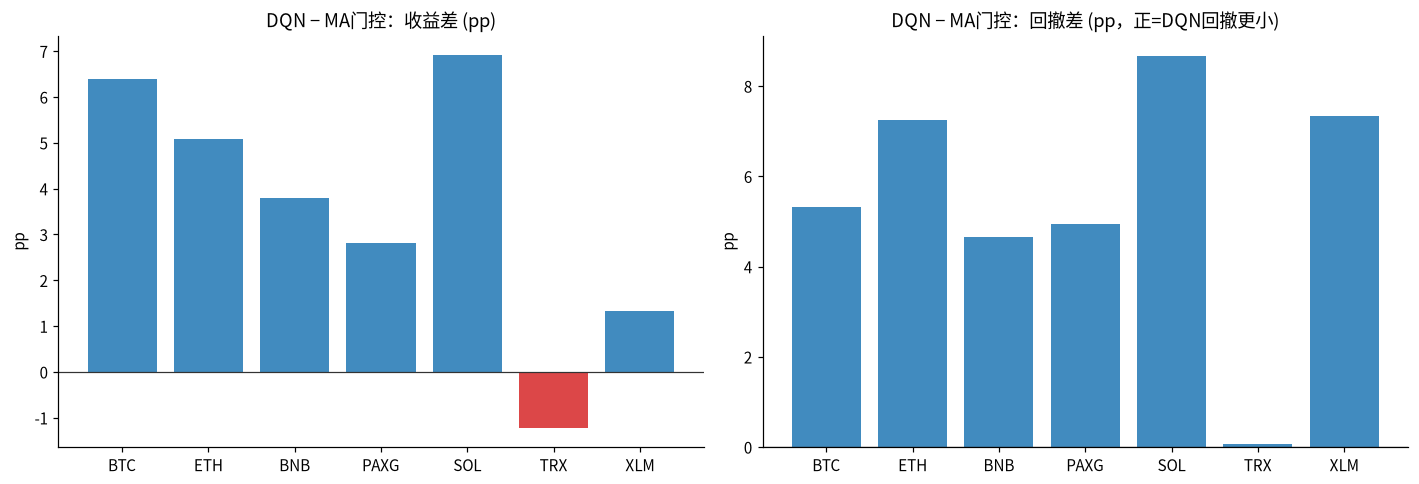

In [8]:
# ================= 图3：DQN 相对 MA 门控的收益/回撤改进 =================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
d_ret = (df["rl_ret"] - df["ma_gate_ret"]) * 100
d_dd = (df["rl_dd"] - df["ma_gate_dd"]) * 100
colors = ["#d62728" if v < 0 else "#1f77b4" for v in d_ret]
axes[0].bar(coins, d_ret, color=colors, alpha=0.85)
axes[0].axhline(0, color="#333", lw=0.8)
axes[0].set_title("DQN − MA门控：收益差 (pp)")
axes[0].set_ylabel("pp")
colors2 = ["#d62728" if v < 0 else "#1f77b4" for v in d_dd]
axes[1].bar(coins, d_dd, color=colors2, alpha=0.85)
axes[1].axhline(0, color="#333", lw=0.8)
axes[1].set_title("DQN − MA门控：回撤差 (pp，正=DQN回撤更小)")
axes[1].set_ylabel("pp")
plt.tight_layout()
plt.show()

## 初步结论

1. **DQN 门控的回撤控制优势在七币种上复现**：全部 7 个币种的最大回撤都小于 MA 门控；相对永不撤单也是 7/7 回撤更小。
2. **收益方面，DQN 门控优于 MA 门控 6/7**，仅在 TRX 上略低（+1.70% vs +2.93%）；相对永不撤单为 4/7。
3. **风险资产（BTC/ETH/BNB/SOL/XLM）普遍下跌**：DQN 在下跌行情中发挥防守价值；但 ETH/BNB/SOL 的 Sharpe 仍为负，说明门控只能减亏，不能逆势。
4. **PAXG（黄金代币，低波动）是例外**：DQN 收益 +13.18%、回撤仅 -1.48%，夏普 3.30，远超 MA 门控；但低于永不撤单（+19.44%），说明在低波动品种上 DQN 仍偏保守。
5. **TRX/XLM 出现明显抖单**：XLM 切换 764 次，TRX 348 次；低价格/低流动性品种的网格和门控噪声更大。
6. **普遍规律**：DQN 门控更适合作为“回撤控制开关”使用；在趋势上涨或超低波动行情中，永不撤单网格的进攻性更强。

**下一步**：对表现较差的币种做分行情分析；对 XLM/TRX 加入最短持有期；对 PAXG 单独调低 DQN 保守度（如减小切换惩罚）；并在多币种上做多种子验证。